## PRCP-1020-HousePricePred

## Importing the Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

random_state = 42
np.random.seed(random_state)

## Fetching the Dataset

In [2]:
df = pd.read_csv("house price prediction dataset.csv")
df.head(10)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
5,6,50,RL,85.0,14115,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,MnPrv,Shed,700,10,2009,WD,Normal,143000
6,7,20,RL,75.0,10084,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,307000
7,8,60,RL,NaN,10382,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,Shed,350,11,2009,WD,Normal,200000
8,9,50,RM,51.0,6120,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2008,WD,Abnorml,129900
9,10,190,RL,50.0,7420,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,1,2008,WD,Normal,118000


In [3]:
display(df.describe(include="all").T.head(20))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Id,1460.0,NaN,NaN,NaN,730.5,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,NaN,NaN,NaN,56.89726,42.300571,20.0,20.0,50.0,70.0,190.0
MSZoning,1460,5,RL,1151,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LotFrontage,1201.0,NaN,NaN,NaN,70.049958,24.284752,21.0,59.0,69.0,80.0,313.0
LotArea,1460.0,NaN,NaN,NaN,10516.828082,9981.264932,1300.0,7553.5,9478.5,11601.5,215245.0
Street,1460,2,Pave,1454,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Alley,91,2,Grvl,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LotShape,1460,4,Reg,925,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LandContour,1460,4,Lvl,1311,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Utilities,1460,2,AllPub,1459,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Task 1:- Prepare a complete data analysis report on the given data.

## Exploratory Data Analysis

In [4]:
#checking duplicate rows in DF
print("Duplicate rows:", int(df.duplicated().sum())) 
#checking duplicate values in DF
print("Duplicate IDs:", int(df["Id"].duplicated().sum()))

Duplicate rows: 0
Duplicate IDs: 0


In [5]:
#data types
display(df.dtypes.astype(str).value_counts().rename_axis("dtype").to_frame("count"))

,count
dtype,
object,43
int64,35
float64,3


In [6]:
null_values = df.isna().sum().to_frame("null_count")
null_values["null_percentage"] = (null_values["null_count"] / len(df) * 100).round(2)
null_values = null_values.sort_values("null_percentage", ascending=False)
display(null_values[null_values["null_count"] > 0].head(25))

,null_count,null_percentage
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageYrBlt,81,5.55
GarageCond,81,5.55
GarageType,81,5.55


In [7]:
if "SalePrice" not in df.columns:
    raise ValueError("The target column 'SalePrice' is missing.")
if (df["SalePrice"] <= 0).any():
    print("Warning: non-positive target values exist; log-target modelling will need review.")
df.head(10)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
5,6,50,RL,85.0,14115,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,MnPrv,Shed,700,10,2009,WD,Normal,143000
6,7,20,RL,75.0,10084,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,307000
7,8,60,RL,NaN,10382,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,Shed,350,11,2009,WD,Normal,200000
8,9,50,RM,51.0,6120,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2008,WD,Abnorml,129900
9,10,190,RL,50.0,7420,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,1,2008,WD,Normal,118000


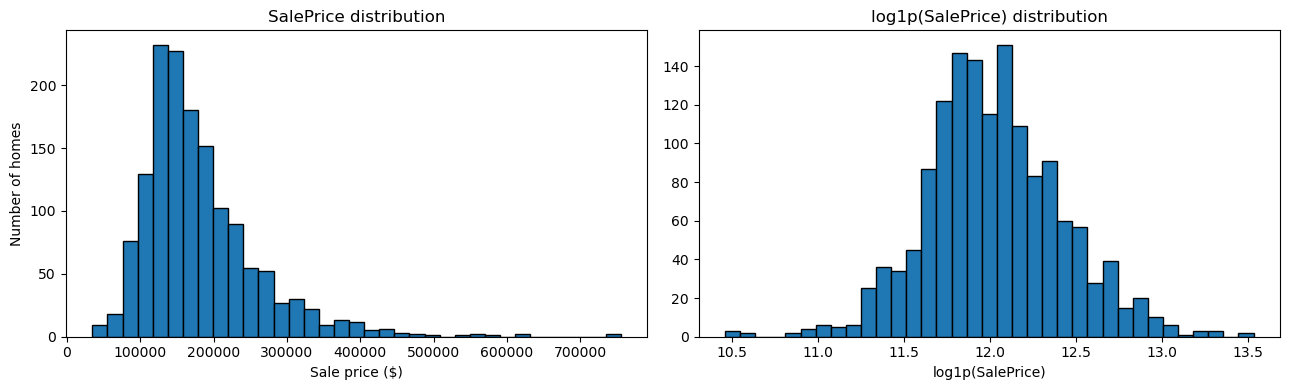

,SalePrice
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
max,755000.000000


Skewness: 1.883


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(df["SalePrice"].dropna(), bins=35, edgecolor="black")
axes[0].set_title("SalePrice distribution")
axes[0].set_xlabel("Sale price ($)")
axes[0].set_ylabel("Number of homes")
axes[1].hist(np.log1p(df["SalePrice"].dropna()), bins=35, edgecolor="black")
axes[1].set_title("log1p(SalePrice) distribution")
axes[1].set_xlabel("log1p(SalePrice)")
plt.tight_layout()
plt.show()

display(df["SalePrice"].describe().to_frame("SalePrice"))
print("Skewness:", round(df["SalePrice"].skew(), 3))

Lowest correlations:


,correlation_with_SalePrice
KitchenAbvGr,-0.135907
EnclosedPorch,-0.128578
MSSubClass,-0.084284
OverallCond,-0.077856
YrSold,-0.028923
LowQualFinSF,-0.025606
MiscVal,-0.021190
BsmtHalfBath,-0.016844
BsmtFinSF2,-0.011378
3SsnPorch,0.044584


Highest correlations:


,correlation_with_SalePrice
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


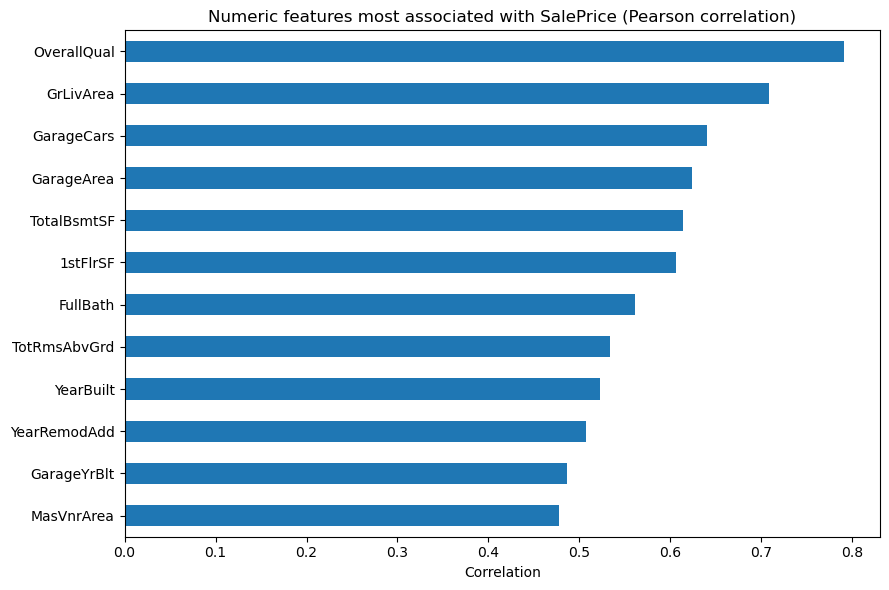

In [9]:
#correlation analysis between numerical features in DataFrame and SalePrice column
numeric = df.select_dtypes(include=np.number).drop(columns=["Id"], errors="ignore")
corr = numeric.corr(numeric_only=True)["SalePrice"].drop("SalePrice").sort_values()
print("Lowest correlations:")
display(corr.head(12).to_frame("correlation_with_SalePrice"))
print("Highest correlations:")
display(corr.tail(15).sort_values(ascending=False).to_frame("correlation_with_SalePrice"))

top_corr = corr.abs().sort_values(ascending=False).head(12).index
plt.figure(figsize=(9, 6))
corr.loc[top_corr].sort_values().plot(kind="barh")
plt.title("Numeric features most associated with SalePrice (Pearson correlation)")
plt.xlabel("Correlation")
plt.tight_layout()
plt.show()

## Task 2:- 
     a) Create a robust machine learning algorithm to accurately predict the price of the house given the various factors across the market.

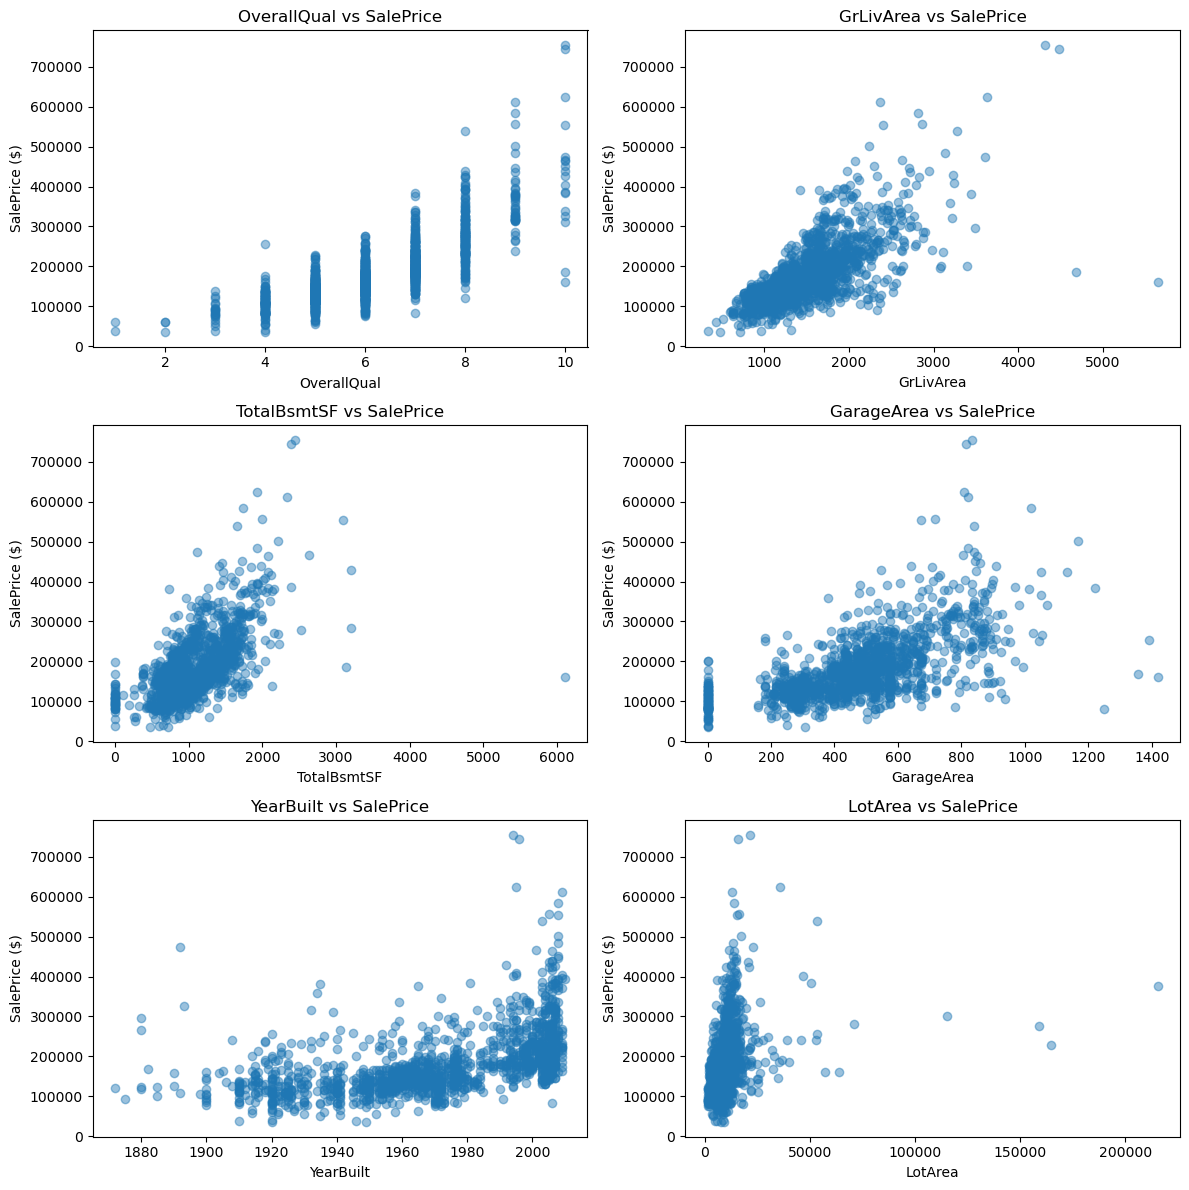

In [10]:
#non-linear patterns and possible outliers
candidate_features = [c for c in ["OverallQual", "GrLivArea", "TotalBsmtSF", "GarageArea", "YearBuilt", "LotArea"] if c in df.columns]
n = len(candidate_features)
fig, axes = plt.subplots((n + 1)//2, 2, figsize=(12, 4*((n+1)//2)))
axes = np.array(axes).reshape(-1)
for ax, col in zip(axes, candidate_features):
    ax.scatter(df[col], df["SalePrice"], alpha=0.45)
    ax.set_xlabel(col)
    ax.set_ylabel("SalePrice ($)")
    ax.set_title(f"{col} vs SalePrice")
for ax in axes[n:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [11]:
# Category-level price summaries for useful categorical factors.
categorical_candidates = [c for c in ["Neighborhood", "ExterQual", "KitchenQual", "HouseStyle", "GarageType", "CentralAir"] if c in df.columns]
for col in categorical_candidates:
    summary = (df.groupby(col, dropna=False)["SalePrice"]
                 .agg(["count", "median", "mean"])
                 .sort_values("median", ascending=False))
    print(f"\n{col}: median sale price by category (showing up to 15 groups)")
    display(summary.head(15).round(0))


Neighborhood: median sale price by category (showing up to 15 groups)


,count,median,mean
Neighborhood,,,
NridgHt,77,315000.0,316271.0
NoRidge,41,301500.0,335295.0
StoneBr,25,278000.0,310499.0
Timber,38,228475.0,242247.0
Somerst,86,225500.0,225380.0
Veenker,11,218000.0,238773.0
Crawfor,51,200624.0,210625.0
ClearCr,28,200250.0,212565.0
CollgCr,150,197200.0,197966.0



ExterQual: median sale price by category (showing up to 15 groups)


,count,median,mean
ExterQual,,,
Ex,52,364606.0,367361.0
Gd,488,220000.0,231634.0
TA,906,139450.0,144341.0
Fa,14,82250.0,87985.0



KitchenQual: median sale price by category (showing up to 15 groups)


,count,median,mean
KitchenQual,,,
Ex,100,316750.0,328555.0
Gd,586,201400.0,212116.0
TA,735,137000.0,139963.0
Fa,39,115000.0,105565.0


... (2 outputs left out)


GarageType: median sale price by category (showing up to 15 groups)


,count,median,mean
GarageType,,,
BuiltIn,88,227500.0,254752.0
Attchd,870,185000.0,202893.0
2Types,6,159000.0,151283.0
Basment,19,148000.0,160571.0
Detchd,387,129500.0,134091.0
CarPort,9,108000.0,109962.0
NaN,81,100000.0,103317.0



CentralAir: median sale price by category (showing up to 15 groups)


,count,median,mean
CentralAir,,,
Y,1365,168000.0,186187.0
N,95,98000.0,105264.0


# Train-Test Split

In [12]:
from sklearn.model_selection import train_test_split, KFold, cross_val_score
X = df.drop(columns=["SalePrice", "Id"], errors="ignore").copy()
y = df["SalePrice"].astype(float).copy()

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

In [14]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler

try:
    encoder = OneHotEncoder(handle_unknown="ignore", min_frequency=2, sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown="ignore", min_frequency=2, sparse=False)

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

numeric_pipeline = Pipeline(steps=[("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
categorical_pipeline = Pipeline(steps=[("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", encoder)])
preprocessor = ColumnTransformer(transformers=[("numeric", numeric_pipeline, numeric_features), ("categorical", categorical_pipeline, categorical_features)], remainder="drop")

print(f"Training rows: {len(X_train)} | Test rows: {len(X_test)}")
print(f"Numeric features: {len(numeric_features)} | Categorical features: {len(categorical_features)}")

Training rows: 1168 | Test rows: 292
Numeric features: 36 | Categorical features: 43


## Training and comparing the multiple models

In [16]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

#Training on log prices to reduce the influence of the right-skewed target and the Predictions are transformed back to dollars before business-facing metrics are calculated


models = {"Baseline (median)": DummyRegressor(strategy="median"),
        "Ridge Regression": Ridge(alpha=20.0),
        "Random Forest": RandomForestRegressor(
            n_estimators=350, min_samples_leaf=2, max_features=0.8,
            random_state=RANDOM_STATE, n_jobs=-1),
        "Extra Trees": ExtraTreesRegressor(
            n_estimators=350, min_samples_leaf=2, max_features=0.9,
            random_state=RANDOM_STATE, n_jobs=-1),
        "Gradient Boosting": GradientBoostingRegressor(
            n_estimators=250, learning_rate=0.035, max_depth=2,
            loss="huber", random_state=RANDOM_STATE),
        "Hist Gradient Boosting": HistGradientBoostingRegressor(
            max_iter=250, learning_rate=0.06, max_leaf_nodes=20,
            l2_regularization=1.0, random_state=RANDOM_STATE)}

fitted_models = {}
predictions = {}
rows = []

In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone

for name, estimator in models.items():
    pipe = Pipeline(steps=[("preprocessor", clone(preprocessor)), ("model", estimator)])
    
    # Fit on log1p price. The baseline also works on the transformed target.
    pipe.fit(X_train, np.log1p(y_train))
    pred_log = pipe.predict(X_test)
    pred = np.maximum(0, np.expm1(pred_log))
    fitted_models[name] = pipe
    predictions[name] = pred
    rows.append({
        "Model": name,
        "MAE ($)": mean_absolute_error(y_test, pred),
        "RMSE ($)": mean_squared_error(y_test, pred) ** 0.5,
        "R2": r2_score(y_test, pred),
        "Median absolute error ($)": float(np.median(np.abs(y_test.to_numpy() - pred)))})

comparison = pd.DataFrame(rows).sort_values("RMSE ($)").reset_index(drop=True)
display(comparison.style.format({
    "MAE ($)": "${:,.0f}", "RMSE ($)": "${:,.0f}",
    "R2": "{:.3f}", "Median absolute error ($)": "${:,.0f}"}))
best_name = comparison.loc[0, "Model"]
best_model = fitted_models[best_name]
best_pred = predictions[best_name]
print("Best model by held-out RMSE:", best_name)

,Model,MAE ($),RMSE ($),R2,Median absolute error ($)
0,Ridge Regression,"$16,561","$25,426",0.916,"$10,740"
1,Extra Trees,"$17,315","$27,625",0.901,"$10,636"
2,Hist Gradient Boosting,"$16,239","$28,253",0.896,"$9,443"
3,Random Forest,"$17,050","$29,330",0.888,"$9,843"
4,Gradient Boosting,"$17,961","$33,521",0.854,"$11,347"
5,Baseline (median),"$59,568","$88,667",-0.025,"$40,000"


Best model by held-out RMSE: Ridge Regression


## Task 2:-     
     b) Determine the relationship between the house features and how the price varies based on this.

## How features relate to price

,feature,importance
16,OverallQual,0.042354
45,GrLivArea,0.024210
60,GarageCars,0.016234
42,1stFlrSF,0.010807
11,Neighborhood,0.010594
17,OverallCond,0.009723
43,2ndFlrSF,0.009692
18,YearBuilt,0.008866
32,BsmtFinType1,0.005256
1,MSZoning,0.005074


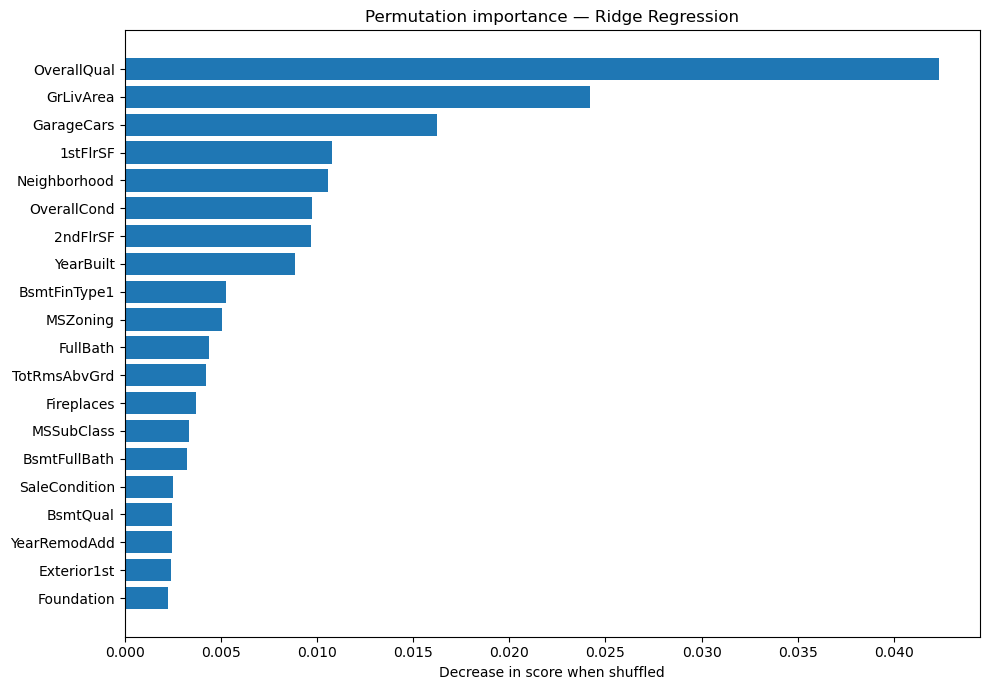

In [18]:
# Tree models provide impurity-based importance. For a non-tree selected model,
# use permutation importance on a manageable test sample.
from sklearn.inspection import permutation_importance

selected_estimator = best_model.named_steps["model"]
selected_preprocessor = best_model.named_steps["preprocessor"]

if hasattr(selected_estimator, "feature_importances_"):
    feature_names = selected_preprocessor.get_feature_names_out()
    importances = selected_estimator.feature_importances_
    importance_df = pd.DataFrame({"feature": feature_names, "importance": importances})
    importance_df = importance_df.sort_values("importance", ascending=False).head(20)
    display(importance_df)
    plt.figure(figsize=(10, 7))
    plt.barh(importance_df["feature"][::-1], importance_df["importance"][::-1])
    plt.title(f"Top encoded feature importances — {best_name}")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()
else:
    # Permutation importance at original input-column level is model-agnostic.
    sample_n = min(300, len(X_test))
    perm = permutation_importance(
        best_model, X_test.iloc[:sample_n], np.log1p(y_test.iloc[:sample_n]),
        n_repeats=5, random_state=RANDOM_STATE, scoring="neg_mean_absolute_error"
    )
    importance_df = pd.DataFrame({
        "feature": X_test.columns,
        "importance": perm.importances_mean
    }).sort_values("importance", ascending=False).head(20)
    display(importance_df)
    plt.figure(figsize=(10, 7))
    plt.barh(importance_df["feature"][::-1], importance_df["importance"][::-1])
    plt.title(f"Permutation importance — {best_name}")
    plt.xlabel("Decrease in score when shuffled")
    plt.tight_layout()
    plt.show()

## Task3:- Come up with suggestions for the customer to buy the house according to the area, price and other requirements.

## Buyer-oriented area and price recommendations

In [19]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone

for name, estimator in models.items():
    pipe = Pipeline(steps=[("preprocessor", clone(preprocessor)), ("model", estimator)])
    
    # Fit on log1p price. The baseline also works on the transformed target.
    pipe.fit(X_train, np.log1p(y_train))
    pred_log = pipe.predict(X_test)
    pred = np.maximum(0, np.expm1(pred_log))
    fitted_models[name] = pipe
    predictions[name] = pred
    rows.append({
        "Model": name,
        "MAE ($)": mean_absolute_error(y_test, pred),
        "RMSE ($)": mean_squared_error(y_test, pred) ** 0.5,
        "R2": r2_score(y_test, pred),
        "Median absolute error ($)": float(np.median(np.abs(y_test.to_numpy() - pred)))})

comparison = pd.DataFrame(rows).sort_values("RMSE ($)").reset_index(drop=True)
display(comparison.style.format({
    "MAE ($)": "${:,.0f}", "RMSE ($)": "${:,.0f}",
    "R2": "{:.3f}", "Median absolute error ($)": "${:,.0f}"}))
best_name = comparison.loc[0, "Model"]
best_model = fitted_models[best_name]
best_pred = predictions[best_name]
print("Best model by held-out RMSE:", best_name)

,Model,MAE ($),RMSE ($),R2,Median absolute error ($)
0,Ridge Regression,"$16,561","$25,426",0.916,"$10,740"
1,Ridge Regression,"$16,561","$25,426",0.916,"$10,740"
2,Extra Trees,"$17,315","$27,625",0.901,"$10,636"
3,Extra Trees,"$17,315","$27,625",0.901,"$10,636"
4,Hist Gradient Boosting,"$16,239","$28,253",0.896,"$9,443"
5,Hist Gradient Boosting,"$16,239","$28,253",0.896,"$9,443"
6,Random Forest,"$17,050","$29,330",0.888,"$9,843"
7,Random Forest,"$17,050","$29,330",0.888,"$9,843"
8,Gradient Boosting,"$17,961","$33,521",0.854,"$11,347"
9,Gradient Boosting,"$17,961","$33,521",0.854,"$11,347"


Best model by held-out RMSE: Ridge Regression


,homes_sold,median_price,mean_price,lower_quartile,upper_quartile
Neighborhood,,,,,
MeadowV,17,"$88,000","$98,576","$83,500","$115,000"
IDOTRR,37,"$103,000","$100,124","$81,000","$120,500"
BrDale,16,"$106,000","$104,494","$91,000","$118,000"
OldTown,113,"$119,000","$128,225","$105,900","$140,000"
Edwards,100,"$121,750","$128,220","$101,500","$145,225"
BrkSide,58,"$124,300","$124,834","$100,500","$141,175"
Sawyer,74,"$135,000","$136,793","$127,250","$149,462"
Blueste,2,"$137,500","$137,500","$130,750","$144,250"
SWISU,25,"$139,500","$142,591","$128,000","$160,000"


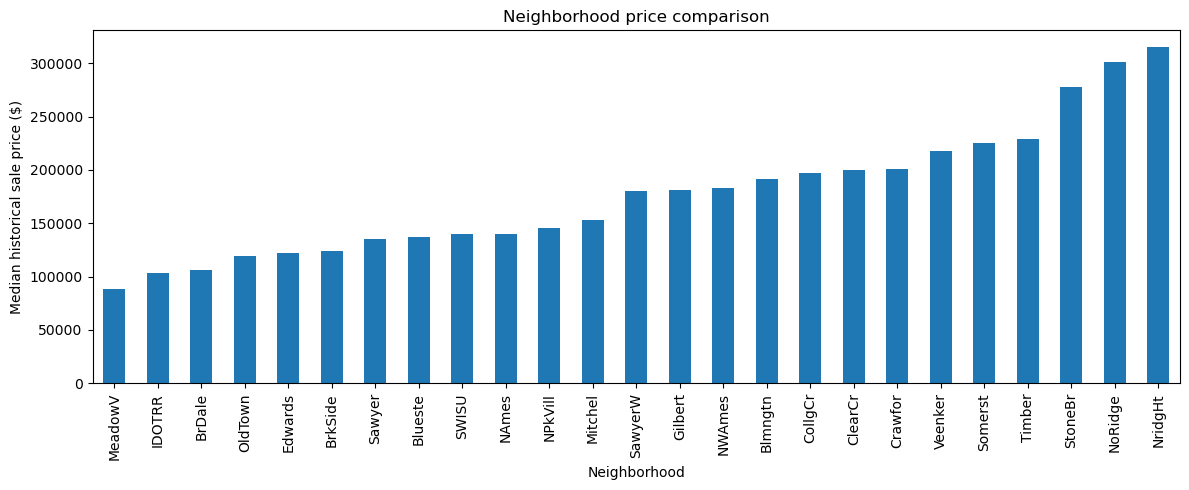

In [20]:
# Neighborhood-level summaries are useful for shortlisting areas, but do not replace
# a buyer's budget, commute, school, safety, condition, or inspection requirements.

if "Neighborhood" in df.columns:
    neighborhood_summary = (
        df.groupby("Neighborhood")["SalePrice"]
          .agg(homes_sold="count", median_price="median", mean_price="mean",
               lower_quartile=lambda s: s.quantile(0.25),
               upper_quartile=lambda s: s.quantile(0.75))
          .sort_values("median_price")
    )
    display(neighborhood_summary.style.format({
        "median_price": "${:,.0f}", "mean_price": "${:,.0f}",
        "lower_quartile": "${:,.0f}", "upper_quartile": "${:,.0f}"
    }))
    neighborhood_summary["median_price"].plot(kind="bar", figsize=(12, 5))
    plt.ylabel("Median historical sale price ($)")
    plt.title("Neighborhood price comparison")
    plt.tight_layout()
    plt.show()
else:
    neighborhood_summary = None
    print("Neighborhood column is not available.")

In [21]:
# A simple, editable buyer shortlist tool based on historical sales in the dataset.
# Set a realistic budget and optional minimum quality preference.

BUYER_BUDGET = 200000
MIN_OVERALL_QUALITY = 5
MAX_RESULTS = 10

buyer_data = df.copy()
if "OverallQual" in buyer_data.columns:
    buyer_data = buyer_data[buyer_data["OverallQual"] >= MIN_OVERALL_QUALITY]
buyer_data = buyer_data[buyer_data["SalePrice"] <= BUYER_BUDGET]

sort_cols = [c for c in ["SalePrice", "OverallQual", "GrLivArea"] if c in buyer_data.columns]
ascending = [True if c == "SalePrice" else False for c in sort_cols]
shortlist_cols = [c for c in [
    "Neighborhood", "SalePrice", "OverallQual", "GrLivArea", "BedroomAbvGr",
    "FullBath", "YearBuilt", "GarageCars", "TotalBsmtSF"
] if c in buyer_data.columns]

buyer_shortlist = buyer_data.sort_values(sort_cols, ascending=ascending)[shortlist_cols].head(MAX_RESULTS)
print(f"Historical homes at or below ${BUYER_BUDGET:,.0f}, with OverallQual >= {MIN_OVERALL_QUALITY}:")
display(buyer_shortlist)

Historical homes at or below $200,000, with OverallQual >= 5:


,Neighborhood,SalePrice,OverallQual,GrLivArea,BedroomAbvGr,FullBath,YearBuilt,GarageCars,TotalBsmtSF
812,IDOTRR,55993,5,1044,2,1,1952,2,540
410,Edwards,60000,5,1276,3,1,1958,1,1276
462,Sawyer,62383,5,864,3,1,1965,1,864
874,OldTown,66500,5,1131,3,1,1941,1,676
398,IDOTRR,67000,5,1077,2,1,1920,1,961
264,OldTown,73000,5,764,2,1,1925,2,680
383,SawyerW,76000,6,784,2,1,1928,2,784
329,IDOTRR,78000,5,1192,3,1,1920,1,596
155,Edwards,79000,6,1096,2,1,1924,0,572
242,OldTown,79000,5,1440,3,1,1900,1,540


## Model Comparison Report

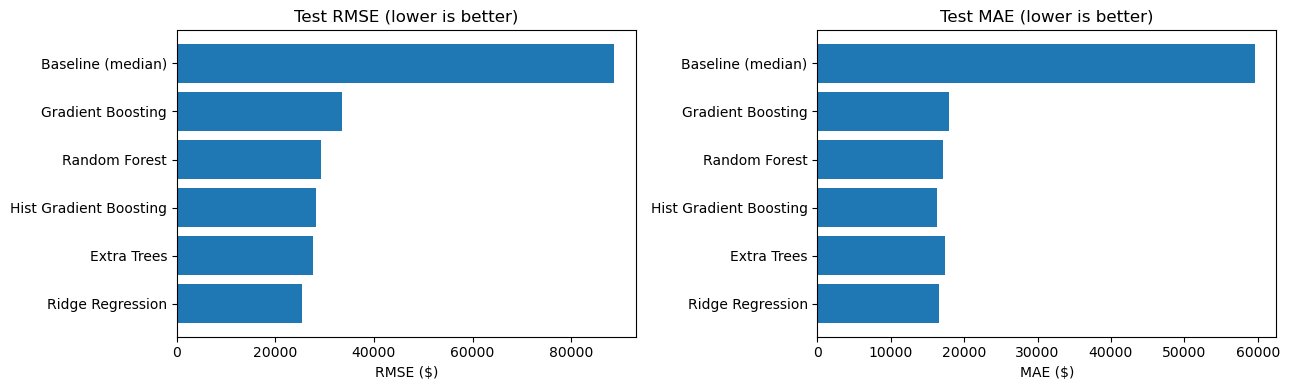

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_data = comparison.sort_values("RMSE ($)", ascending=True)
axes[0].barh(plot_data["Model"], plot_data["RMSE ($)"])
axes[0].set_title("Test RMSE (lower is better)")
axes[0].set_xlabel("RMSE ($)")
axes[1].barh(plot_data["Model"], plot_data["MAE ($)"])
axes[1].set_title("Test MAE (lower is better)")
axes[1].set_xlabel("MAE ($)")
plt.tight_layout()
plt.show()

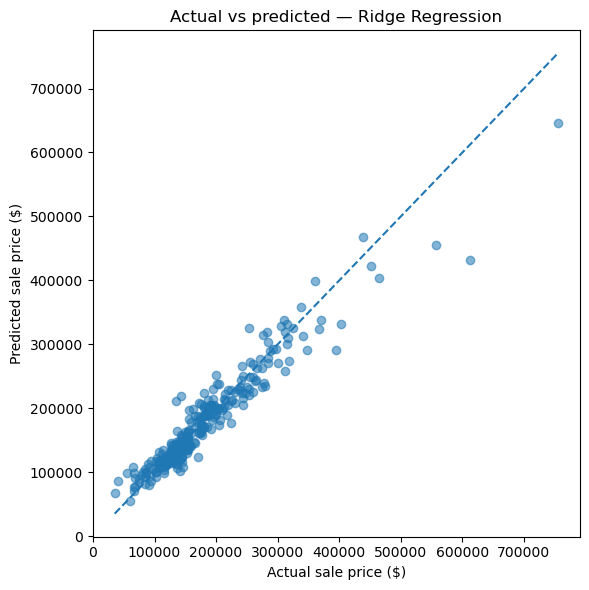

In [23]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_pred, alpha=0.55)
low = min(y_test.min(), best_pred.min())
high = max(y_test.max(), best_pred.max())
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual sale price ($)")
plt.ylabel("Predicted sale price ($)")
plt.title(f"Actual vs predicted — {best_name}")
plt.tight_layout()
plt.show()

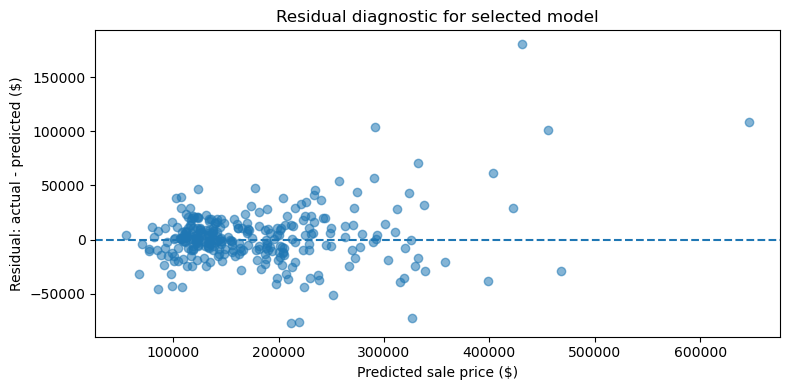

In [24]:
residuals = y_test.to_numpy() - best_pred
plt.figure(figsize=(8, 4))
plt.scatter(best_pred, residuals, alpha=0.55)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted sale price ($)")
plt.ylabel("Residual: actual - predicted ($)")
plt.title("Residual diagnostic for selected model")
plt.tight_layout()
plt.show()

## Challenges Faced and Techniques Used

1\. Missing Values: The dataset contained missing values in some columns. To handle this, median values were used for numerical columns, while the most common values were used for categorical columns. This helped us prepare the data for machine learning without removing too many records.

2\. Different Types of Data: The dataset contained both numerical data, such as house area and year built, and categorical data, such as neighborhood and house style. We used separate preprocessing methods for these types. One-hot encoding was used to convert categorical data into a numerical format that machine learning models can understand.

3\. Uneven Distribution of House Prices: Some houses were much more expensive than others, making the price distribution uneven. To handle this, we applied a logarithmic transformation to house prices during training. This helped reduce the influence of very expensive houses on the model.

4\. Data Leakage: Data leakage happens when information from the test data influences the model during training. To prevent this, we split the dataset into training and testing sets before applying preprocessing steps. This helped us evaluate the model more fairly on unseen data.

5\. Many Categories in the Dataset: Some features contained many different categories. We used one-hot encoding to represent these categories and configured it to handle new or uncommon categories. This made the model more reliable when encountering categories that were not common in the training data.

6\. Complex Relationships Between Features: House prices depend on several factors, and their relationships are not always simple. For example, price may depend on the size, quality, and location of a house together. We compared different machine learning algorithms, including Random Forest and Gradient Boosting, to identify models capable of learning these complex relationships.

7\. Outliers and Prediction Errors: Some houses had unusually high prices or characteristics that differed from most properties. We evaluated model performance using MAE, RMSE, and R², along with residual plots. These methods helped us understand how far the predictions were from the actual prices and identify areas where the model performed poorly.

8\. Limited Dataset Size: The dataset contained a limited number of houses compared with the number of available features. We used a training and testing split along with five-fold cross-validation to evaluate model performance more reliably. However, the model may still perform differently when applied to new housing data.

9\. Relationship Between Location and House Quality: House prices can vary according to both neighborhood and property quality. A house in an expensive neighborhood may cost more than a similar house elsewhere. We used neighborhood-wise price comparisons and feature importance analysis to understand these relationships, while recognizing that these patterns do not necessarily prove cause and effect.

10\. Historical and Location-Specific Data: The dataset contains historical house sales from Ames, Iowa. Housing prices and buyer preferences can change over time and differ between locations. Therefore, the model should be tested with recent local housing data before being used to estimate prices in other markets.